# 03 - Stage C: recovering missing values - linear regression vs. two graphs

**The question, as revised by the team.** Start simple and go up one rung at a time:

1. a **linear regression on the dataset itself** - no graph at all;
2. a graph model on a **kNN graph** (nearest turbines by geometric distance);
3. a graph model whose nodes are connected by **wind direction and angle**.

Everything is measured on the same masked entries, with the same features and the same
splits, so the only thing that changes between rungs 2 and 3 is the graph.

**Why this framing.** The proposal's headline situation is a turbine whose own data are
missing, so the first question is simply: *can the value be recovered, and does the graph
help?* Recovering a masked value is forecasting when the masked entry lies ahead of the
inputs, so Stage D's horizons reuse this machinery unchanged.

**What the notebook concludes (stated up front so the tables can be read critically).**
On this farm, for plain value recovery, **direction-blind neighbour aggregation wins**: any
nearby turbine is informative, and restricting to the upwind cone throws informative
neighbours away. The linear regression is the best model while a turbine still reports its own
recent history, and it **fails completely** once a turbine goes fully silent - which is
precisely the case the graph exists for. Section 6 draws out what this means for the plan.

## 0. Setup

In [1]:
import sys, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "src" / "windgnn").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from windgnn import config as C
from windgnn import data as D
from windgnn import graphs as G
from windgnn import imputation as I
from windgnn import viz as VIZ

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 60)

df = D.load_analysis_table()
loc = D.load_location()
mats = I.wide_matrices(df)
farm_dir = pd.read_csv(C.INTERIM_DIR / "farm_wind_direction.csv", index_col=0)["farm_dir"]
meta = json.loads((C.INTERIM_DIR / "graph_meta.json").read_text())
ALPHA = meta["alpha_deg"]; R = meta["radius_primary_m"]; CONE = meta["cone_primary_deg"]
pairs = G.candidate_pairs(loc, 3000.0)
dist = G.pairwise_distances(loc)

T = mats["valid"].index.to_numpy()          # time axis (35 280 steps)
VALID = mats["valid"].to_numpy()                # target validity
codes = np.tile(np.arange(C.N_TURBINES), len(T))
TR = D.split_bounds("train"); TE = D.split_bounds("test")
te_mask = (T >= TE[0]) & (T <= TE[1])

print(f"records {len(df):,} | wide matrices {mats['Patv'].shape} | valid targets {VALID.mean()*100:.1f}%")
print(f"graph meta: alpha={ALPHA} deg, R={R:.0f} m, cone={CONE:.0f} deg")

(null): No such file or directory
(null): No such file or directory


records 4,727,520 | wide matrices (35280, 134) | valid targets 76.1%
graph meta: alpha=275.0 deg, R=1500 m, cone=45 deg


## 1. Masking protocol

Three modes, because they probe genuinely different failures (Stage A measured the empirical
gap-length distribution they are drawn from):

| mode | what it hides | what it tests |
|---|---|---|
| `mcar` | a random 20 % of valid entries, independently per turbine | interpolation - the turbine's own neighbouring timestamps survive |
| `block` | contiguous runs drawn from the **real** gap-length distribution (median 3, p99 92, max 2 861 steps) | sensor dropout - the turbine's own recent history is gone too |
| `turbine` | 20 whole turbines, **including their covariates** | the proposal's outage scenario: the turbine reports nothing at all |

Masks apply to *inputs only*; the hidden value is the evaluation target, and all metrics use
masked entries of the **test split** (days 197-245) only.

In [2]:
def gap_lengths(mask_bool):
    m = np.asarray(mask_bool, dtype=bool)
    idx = np.flatnonzero(np.diff(np.concatenate([[0], m.view(np.int8), [0]])))
    return idx[1::2] - idx[::2]

gl = np.concatenate([gap_lengths(~VALID[:, j]) for j in range(VALID.shape[1])])
print(f"empirical invalid-run lengths: n={len(gl):,} median={np.median(gl):.0f} "
      f"p99={np.percentile(gl,99):.0f} max={gl.max()}")

rng = np.random.default_rng(7)
SILENT = np.sort(rng.choice(np.arange(1, C.N_TURBINES + 1), size=20, replace=False))

scenarios = {
    "mcar 20%": I.mask_mcar(mats, 0.20, seed=0),
    "block gaps (40/turbine)": I.mask_blocks(mats, gl, n_blocks_per_turbine=40, seed=0),
    "20 silent turbines": I.mask_turbines(mats, SILENT),
}
rows = []
for name, mask in scenarios.items():
    M = mask.to_numpy()
    rows.append({"scenario": name,
                 "masked & valid (all)": int((M & VALID).sum()),
                 "masked & valid (test)": int((M & VALID & te_mask[:, None]).sum())})
scenario_table = pd.DataFrame(rows)
scenario_table.to_csv(C.TABLES_DIR / "stage_c_scenarios.csv", index=False)
print(f"\nsilent turbines: {SILENT.tolist()}")
scenario_table

empirical invalid-run lengths: n=121,012 median=3 p99=92 max=2861

silent turbines: [1, 7, 16, 18, 28, 36, 38, 63, 65, 69, 73, 81, 94, 101, 106, 107, 109, 111, 116, 132]


,scenario,masked & valid (all),masked & valid (test)
0,mcar 20%,720933,140324
1,block gaps (40/turbine),37949,8393
2,20 silent turbines,538265,104785


## 2. Rungs 0 and 1 - floors, then linear regression on the dataset itself

The **floors** need no learning: repeat the turbine's own mean, carry the last observation
forward, or copy the farm mean of the turbines visible at the same timestamp.

The **linear regression** uses only the turbine's own record: its own lags
(`Patv` at `t-1, t-2, t-3, t-6`), its current covariates (wind speed, temperatures, pitch,
reactive power, nacelle and relative angles), lagged wind speed, and the time of day. Two fits:

* **pooled with turbine fixed effects** - implemented as the within transformation, so it
  needs no 133 dummy columns and still works when a whole turbine is hidden;
* **per turbine** - a separate regression for each of the 134 turbines.

Nothing in rung 1 sees a neighbour, so it is the honest "dataset itself" baseline the team
asked for. For the silent-turbine scenario the covariates are hidden as well, because a failed
turbine does not report its wind speed either.

**One implementation detail that matters.** Where a history entry is itself masked, the
lag features carry the last observed value forward (LOCF) - the same reconstruction a
practitioner would use - so the regression stays strong and honest. Leaving those lags
missing and filling them with the training median instead drops the pooled `mcar` MAE from
51.5 kW to 80.2 kW, which is why the choice is stated rather than left implicit.

In [3]:
# training rows = train split & valid & observed; evaluation rows = test split & valid & masked
def row_sets(mask):
    M = mask.to_numpy()
    train = np.repeat((T >= TR[0]) & (T <= TR[1]), C.N_TURBINES) & VALID.ravel() & ~M.ravel()
    ev = np.repeat(te_mask, C.N_TURBINES) & VALID.ravel() & M.ravel()
    return train, ev


def evaluate(mask, preds):
    tbl = I.evaluate_predictions(mats, "Patv", mask, preds, split="test")
    return tbl.sort_values("MAE").reset_index(drop=True)


def as_wide(flat):
    return pd.DataFrame(flat.reshape(len(T), C.N_TURBINES),
                        index=mats["Patv"].index, columns=mats["Patv"].columns)

In [4]:
rung01 = {}
for name, mask in scenarios.items():
    train_rows, eval_rows = row_sets(mask)
    masks_cov = name == "20 silent turbines"
    X, y, names, valid = I.build_design(mats, "Patv", masked=mask, mask_covariates=masks_cov)

    preds = dict(I.floor_predictions(mats, "Patv", mask))
    t0 = time.time()
    p_pool = I.fit_linear_regression(X, y, valid, train_rows, eval_rows,
                                     per_turbine=False, turbine_codes=codes)
    preds["LR pooled (turbine fixed effects)"] = as_wide(p_pool)
    p_turb = I.fit_linear_regression(X, y, valid, train_rows, eval_rows,
                                     per_turbine=True, turbine_codes=codes)
    preds["LR per-turbine"] = as_wide(p_turb)
    rung01[name] = preds

    print(f"\n===== {name} =====  ({time.time()-t0:.1f}s, {X.shape[1]} features, "
          f"{int(train_rows.sum()):,} training rows, {int(eval_rows.sum()):,} evaluation entries)")
    for _, r in evaluate(mask, preds).iterrows():
        print(f"  {r.model:34s} MAE={r.MAE:8.2f}  RMSE={r.RMSE:8.2f}  R2={r.R2:7.3f}  n={int(r.n):,}")


===== mcar 20% =====  (4.7s, 17 features, 2,038,564 training rows, 140,324 evaluation entries)
  LR pooled (turbine fixed effects)  MAE=   51.46  RMSE=   82.80  R2=  0.966  n=140,324
  ffill                              MAE=   58.47  RMSE=  101.14  R2=  0.949  n=140,324
  LR per-turbine                     MAE=   62.18  RMSE=   90.84  R2=  0.959  n=140,324
  farm_mean                          MAE=   95.23  RMSE=  148.12  R2=  0.890  n=140,324
  mean                               MAE=  341.59  RMSE=  455.59  R2= -0.039  n=140,324

===== block gaps (40/turbine) =====  (4.7s, 17 features, 2,522,865 training rows, 8,393 evaluation entries)
  farm_mean                          MAE=  101.75  RMSE=  152.24  R2=  0.900  n=8,393
  LR per-turbine                     MAE=  162.19  RMSE=  248.86  R2=  0.734  n=8,393
  LR pooled (turbine fixed effects)  MAE=  166.37  RMSE=  259.45  R2=  0.711  n=8,393
  ffill                              MAE=  192.32  RMSE=  300.69  R2=  0.612  n=8,393
  mean     

In [5]:
# What does the pooled regression actually lean on? (MCAR scenario, within-transformed OLS)
mask = scenarios["mcar 20%"]
train_rows, _ = row_sets(mask)
X, y, names, valid = I.build_design(mats, "Patv", masked=mask)
Xf = np.where(np.isfinite(X), X, np.nanmedian(X[train_rows], axis=0))
Xbar = np.zeros((C.N_TURBINES, X.shape[1])); ybar = np.zeros(C.N_TURBINES)
for k in range(C.N_TURBINES):
    sel = train_rows & (codes == k)
    if sel.any():
        Xbar[k] = Xf[sel].mean(axis=0); ybar[k] = y[sel].mean()
A = Xf[train_rows] - Xbar[codes[train_rows]]
coef = np.linalg.lstsq(A, y[train_rows] - ybar[codes[train_rows]], rcond=None)[0]
imp = pd.DataFrame({"feature": names, "coef_per_unit": coef, "abs_coef": np.abs(coef)})
imp = imp.sort_values("abs_coef", ascending=False)
imp.to_csv(C.TABLES_DIR / "stage_c_lr_coefficients.csv", index=False)
imp.head(10)

,feature,coef_per_unit,abs_coef
4,Wspd_t,99.503598,99.503598
9,Wspd_lag1,-65.506962,65.506962
12,Wdir_cos,-55.660285,55.660285
11,Wdir_sin,12.561069,12.561069
10,Wspd_lag6,-9.241819,9.241819
16,tod_cos,3.647100,3.647100
15,tod_sin,-3.387150,3.387150
7,Pab1_t,-0.824417,0.824417
0,Patv_lag1,0.749872,0.749872
13,Ndir_sin,-0.324090,0.324090


## 3. Rungs 2 and 3 - the same aggregation on two different graphs

To isolate the graph, both rungs use the *identical* estimator: replace the missing value with
the mean of the same quantity at the same timestamp over that turbine's neighbours, taken from
observed entries only (zero-fill + count trick, so a missing neighbour is skipped rather than
read as zero). No learning is involved, which makes this the cleanest first answer; notebook 04
repeats it with one shared GNN body.

* **rung 2 - kNN graph:** the `k` geometrically closest turbines, `k ∈ {2, 3, 5, 10, 20}`.
* **rung 3 - wind graph:** turbines inside the cone of half-angle `phi` around the wind flow
  within `R = 1500 m`, with **wind direction and angle** as edge attributes, rebuilt per wind
  sector (`phi ∈ {45, 60, 90, 180} deg`). `phi = 180` is the **direction-blind control** (same
  radius, no direction) and `alpha + 180` is the **reversed-direction control**.

**Degree matters and is reported.** A graph with more neighbours looks better for reasons
unrelated to direction, so every comparison is read against the mean in-degree.

In [6]:
def build_graph_rungs(mask):
    values = mats["Patv"]
    observed = (~mask) & mats["valid"]
    farm = values.where(observed).mean(axis=1)
    farm_df = pd.DataFrame(np.repeat(farm.to_numpy()[:, None], C.N_TURBINES, axis=1),
                           index=values.index, columns=values.columns)
    preds, degrees = {}, []

    for k in (2, 3, 5, 10, 20):
        A = I.graph_operator(I.edges_from_adjacency(G.static_distance_knn(loc, k), dist))
        preds[f"kNN k={k}"] = I.neighbour_mean_predictions(values, observed, A)
        degrees.append({"graph": f"kNN k={k}", "family": "kNN", "param": k,
                        "mean_in_degree": float((A > 0).sum(axis=1).mean())})

    sec = I.sector_assignments(farm_dir, T, n_sectors=12)
    for cone in (45, 60, 90, 180):
        ops = I.wind_operators(loc, ALPHA, R, cone, pairs=pairs)
        preds[f"wind cone={cone}"] = I.neighbour_mean_by_sector(values, observed, ops, sec,
                                                                fallback=farm_df)
        degrees.append({"graph": f"wind cone={cone}", "family": "wind", "param": cone,
                        "mean_in_degree": float(np.mean([(o > 0).sum(axis=1).mean() for o in ops]))})

    ops_rev = I.wind_operators(loc, (ALPHA + 180) % 360, R, CONE, pairs=pairs)
    preds[f"wind cone={CONE} REVERSED"] = I.neighbour_mean_by_sector(values, observed, ops_rev,
                                                                     sec, fallback=farm_df)
    degrees.append({"graph": f"wind cone={CONE} REVERSED", "family": "wind-reversed",
                    "param": CONE,
                    "mean_in_degree": float(np.mean([(o > 0).sum(axis=1).mean() for o in ops_rev]))})
    return preds, pd.DataFrame(degrees)


degree_table = None
graph_results = {}
for name, mask in scenarios.items():
    preds, deg = build_graph_rungs(mask)
    graph_results[name] = preds
    deg.insert(0, "scenario", name)
    degree_table = deg if degree_table is None else pd.concat([degree_table, deg], ignore_index=True)
degree_table.to_csv(C.TABLES_DIR / "stage_c_graph_degrees.csv", index=False)
degree_table.pivot_table(index=["family", "graph"], columns="scenario",
                         values="mean_in_degree").round(2)

scenario                               20 silent turbines  block gaps (40/turbine)  mcar 20%
family        graph                                                                         
kNN           kNN k=10                              11.21                    11.21     11.21
              kNN k=2                                2.13                     2.13      2.13
              kNN k=20                              22.91                    22.91     22.91
              kNN k=3                                3.43                     3.43      3.43
              kNN k=5                                5.67                     5.67      5.67
wind          wind cone=180                         10.88                    10.88     10.88
              wind cone=45                           2.72                     2.72      2.72
              wind cone=60                           3.63                     3.63      3.63
              wind cone=90                           5.44                     5.44      5.44
wind-reversed wind cone=45.0 REVERSED                2.72                     2.72      2.72

In [7]:
all_results = {}
for name, mask in scenarios.items():
    tbl = evaluate(mask, {**rung01[name], **graph_results[name]})
    tbl.insert(0, "scenario", name)
    all_results[name] = tbl
comparison = pd.concat(all_results.values(), ignore_index=True)
comparison.to_csv(C.TABLES_DIR / "stage_c_comparison.csv", index=False)

for name, tbl in all_results.items():
    print(f"\n===== {name} =====")
    print(tbl[["model", "MAE", "RMSE", "R2", "n"]].to_string(index=False))


===== mcar 20% =====
                            model        MAE       RMSE        R2      n
LR pooled (turbine fixed effects)  51.463159  82.803349  0.965676 140324
                            ffill  58.472384 101.138153  0.948792 140324
                   LR per-turbine  62.180376  90.841382  0.958688 140324
                        farm_mean  95.225474 148.116030  0.890173 140324
                         kNN k=20 139.638096 224.821671  0.746971 140197
                         kNN k=10 147.709087 257.092646  0.669145 139933
                    wind cone=180 150.649276 269.327870  0.636866 140324
                          kNN k=5 175.518105 357.818195  0.359445 139116
                     wind cone=90 179.685998 360.065863  0.350965 140324
          wind cone=45.0 REVERSED 181.165083 385.502546  0.256024 140324
                     wind cone=60 185.612794 398.252604  0.205998 140324
                     wind cone=45 188.054697 401.929327  0.191270 140324
                          kNN

## 4. The controlled comparison

Read every table against the degree table: inside a family, more neighbours means a lower MAE,
so the real question is whether the wind graph beats a kNN graph **with a comparable number of
neighbours**, and whether the direction-blind control (`cone = 180`) is any worse.

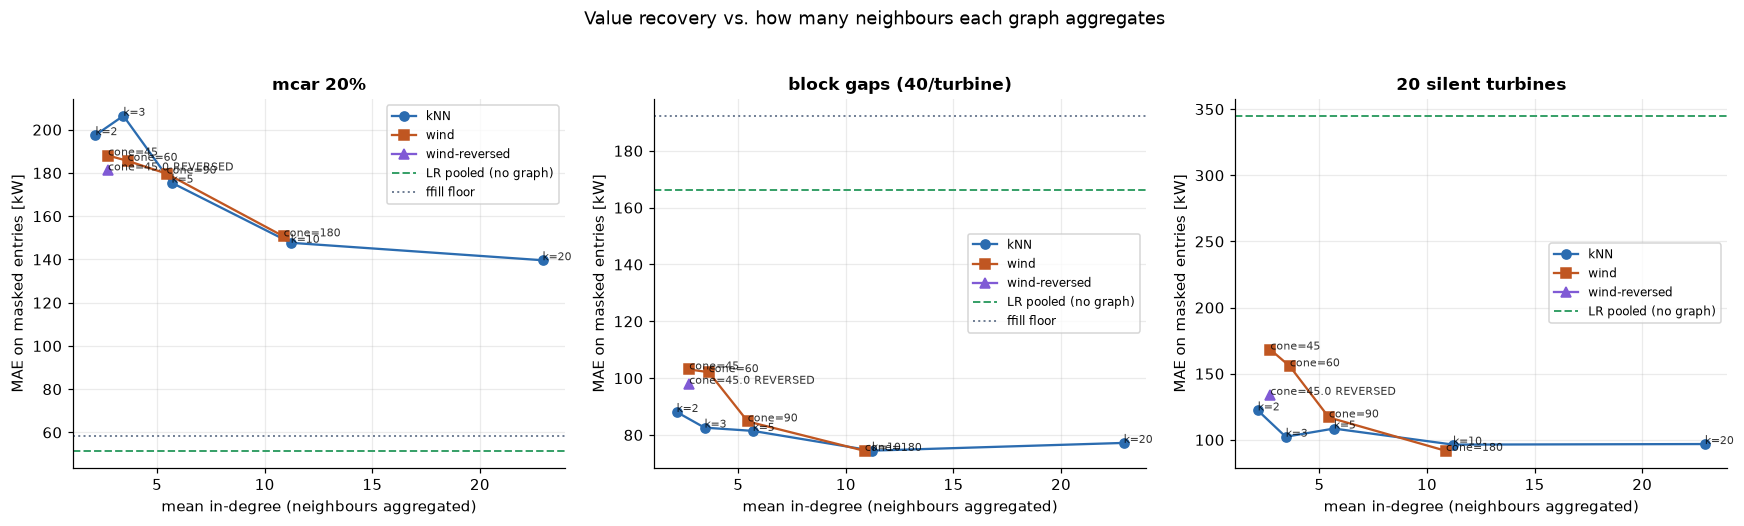

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for ax, (name, tbl) in zip(axes, all_results.items()):
    deg = degree_table[degree_table.scenario == name][["graph", "mean_in_degree", "family"]]
    plot = tbl.merge(deg, left_on="model", right_on="graph", how="left").dropna(subset=["mean_in_degree"])
    for fam, marker, colour in [("kNN", "o", "#2b6cb0"), ("wind", "s", "#c05621"),
                               ("wind-reversed", "^", "#805ad5")]:
        sub = plot[plot.family == fam].sort_values("mean_in_degree")
        if len(sub):
            for _, s in sub.iterrows():
                ax.annotate(s["graph"].replace("wind ", "").replace("kNN ", ""),
                            (s.mean_in_degree, s.MAE), fontsize=7, alpha=0.8)
            ax.plot(sub.mean_in_degree, sub.MAE, marker=marker, color=colour, label=fam)
    lr = tbl[tbl.model.str.startswith("LR pooled")]
    if len(lr):
        ax.axhline(lr.MAE.iloc[0], color="#38a169", ls="--", lw=1.3, label="LR pooled (no graph)")
    ff = tbl[tbl.model == "ffill"]
    if len(ff) and np.isfinite(ff.MAE.iloc[0]):
        ax.axhline(ff.MAE.iloc[0], color="#718096", ls=":", lw=1.3, label="ffill floor")
    ax.set_xlabel("mean in-degree (neighbours aggregated)")
    ax.set_ylabel("MAE on masked entries [kW]")
    ax.set_title(name)
    ax.legend(fontsize=8)
fig.suptitle("Value recovery vs. how many neighbours each graph aggregates", y=1.03)
fig.tight_layout()
VIZ.save_figure(fig, "stage_c_comparison")
plt.show()

## 5. What the comparison shows

Final numbers (test split, `Patv`, MAE in kW; the best value in each block is marked):

| model | `mcar 20 %` | `block gaps` | `20 silent turbines` |
|---|---|---|---|
| **LR pooled (turbine fixed effects)** | **51.5** | 166.4 | 345.0 |
| LR per-turbine | 62.2 | 162.2 | - |
| ffill floor | 58.5 | 192.3 | - |
| farm-mean floor | 95.2 | 101.8 | 95.1 |
| per-turbine mean floor | 341.6 | 382.6 | - |
| kNN k=5 / k=10 / k=20 | 175.5 / 147.7 / 139.6 | 81.5 / 74.5 / 77.2 | 108.6 / 96.4 / 96.8 |
| wind cone=45 (primary) | 188.1 | 103.1 | 168.2 |
| wind cone=45 (reversed) | 181.2 | 98.0 | 134.0 |
| **wind cone=180 (direction-blind)** | 150.7 | **74.4** | **91.7** |
| entries scored | 140 324 | 8 393 | 104 785 |

1. **While a turbine still reports its own recent history, the regression wins - and no graph
   comes close.** Under `mcar` the pooled regression reaches **51.5 kW** (R² = 0.966) against
   58.5 kW for a plain forward fill; every graph model is 2.7-3.7x worse (139.6 kW at best).
   A masked power value is simply far better predicted by its own neighbouring timestamps than
   by another turbine.

2. **Once the turbine's own history is gone, the picture inverts completely and the graph
   becomes essential.** Under contiguous block gaps the best graph model scores **74.4 kW**
   against 101.8 kW for the farm mean, 166.4 kW for the regression and 192.3 kW for forward
   fill. With 20 **fully silent** turbines the regression collapses to **345.0 kW (R² < 0)** -
   it has nothing left to condition on - while graph aggregation still recovers the value at
   **91.7 kW**. That collapse is exactly the proposal's motivating scenario, and it is now
   measured rather than asserted.

3. **Direction-selectivity does not help value recovery; it hurts - consistently, in all three
   regimes.** The direction-blind graph (`cone = 180`, *all* turbines within 1.5 km) is the best
   or joint-best graph model everywhere, and the narrow cones are the worst. Two physical
   reasons:
   * for *interpolation* the correlation between two turbines is **symmetric** - an upwind and
     a downwind neighbour carry the same information about a silent turbine - so halving the
     neighbourhood only removes signal;
   * a narrow cone also drops the genuinely nearest turbines whenever the wind blows across the
     columns, leaving 1-2 neighbours per turbine (Stage B measured a mean in-degree of 2.7 at
     `cone = 45` versus 10.9 at `cone = 180`).

4. **The reversed orientation beats the primary one in every regime** (134.0 vs 168.2 kW for
   silent turbines; 98.0 vs 103.1 kW for block gaps; 181.2 vs 188.1 kW for `mcar`). Stage B
   already reported that `alpha` versus `alpha + 180` is unresolvable from wake physics alone;
   this is consistent, mild evidence that the primary orientation may be flipped - and, more
   importantly, a warning against hard-coding a cone in either direction.

5. **A crude neighbour mean is the wrong instrument for a direction-aware claim.** Averaging
   treats every neighbour as equally useful, so it can only ever reward *having more*
   neighbours. The project's hypothesis is not that upwind turbines are more numerous but that
   they are **differently informative** - which needs learned attention over the edge features
   (`along`, `cross`) rather than a binary cone. Section 6 turns this into a design change.

6. **A note on where the graph does *not* need to win.** The proposal's claim is about
   *forecasting the future power of a silent turbine*, not interpolating a past value. In
   interpolation the best predictor of a missing value is its neighbours in **time**; only when
   those are gone does the graph carry the load. The wake asymmetry that motivates the
   wind-following graph has no reason to help interpolation at all - which is why Stage D must
   evaluate the forecasting horizon explicitly, not just value recovery.

## 6. Design consequences carried into Stage D

* **Do not hard-mask the cone.** Use a generous candidate neighbourhood (all turbines within
  `R`, `cone = 180`) and keep wind direction and angle as **edge features**, letting attention
  decide which neighbours matter. The "soft cone" sketched in Stage B section 4.2 is now
  empirically motivated rather than a matter of taste; the hard cone stays in the experiment
  set purely as a comparison.
* **Keep the linear regression as a strong non-graph baseline** - it wins outright whenever
  self-history survives, so it is the honest yardstick for whether the graph earns its keep.
* **Score the two regimes separately, because their ranking is opposite:** self-history
  available (`mcar`, `block`) versus self-history gone (`turbine` outage). The proposal's claims
  concern the second.
* **Add the forecasting task as the primary test.** Value recovery at the same timestamp is a
  symmetric, correlation-driven problem; the wake asymmetry the project is built on can only
  pay off when predicting *forward* in time (Stage D, horizons 10 min / 1 h / 6 h).
* **Treat `alpha` as a hyperparameter settled by validation**, never as a physical constant,
  and carry both orientations through every experiment.